# 7 · How big is a big fleet?

The exact RMSE ratio against fleet size for good, biased and conflicting priors. See [Lesson 7](../docs/lessons/07-how-big-is-a-big-fleet.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from smallfleet import plotting

plotting.use_style()
rng = np.random.default_rng(1)

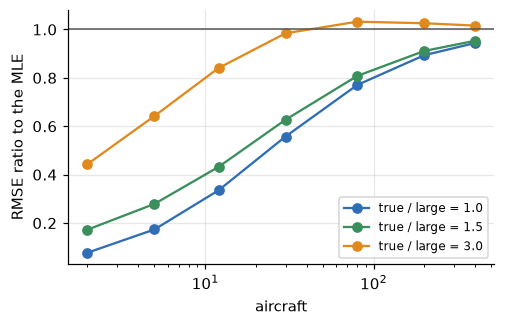

In [2]:
from smallfleet.simulation_study import single_fleet_point

sizes = [2, 5, 12, 30, 80, 200, 400]
fig, ax = plt.subplots(figsize=(5, 3))
for ratio, color in zip((1.0, 1.5, 3.0), plotting.SERIES_COLORS[1:4]):
    pts = [single_fleet_point(n, 0.2 * ratio, 0.2, 35.0, 12, 10_000.0, 900_000.0) for n in sizes]
    r = [p.methods["borrowed prior"].rmse / p.methods["MLE + Garwood"].rmse for p in pts]
    ax.semilogx(sizes, r, "o-", color=color, label=f"true / large = {ratio}")
ax.axhline(1, color=plotting.NEUTRAL_COLOR, lw=1)
ax.set_xlabel("aircraft")
ax.set_ylabel("RMSE ratio to the MLE")
ax.legend(fontsize=8);